# RPDA8412 Research Project Cognitive Load and Student Academic Performance

## 1. Setup and environment

**Research brief (approved proposal):** Tertiary institutions often respond to student underperformance only after poor results appear. This study examines whether **cognitive-load-related factors** — study habits, sleep, stress, prior performance, and competing demands can help **predict academic performance** in a measurable and interpretable way. The analysis uses two synthetic Kaggle datasets and applies **Multiple Linear Regression (MLR)** and **Random Forest Regression** to compare model performance and identify influential predictors (Maher, 2024; Nikhil, 2023).

Both datasets are **secondary, synthetic, and cross-sectional**, so findings are treated as **predictive associations** rather than causal impact. This notebook implements the approved methodology and produces tables and figures for the Research Report Findings section.

**Notebook scope:**

1. Load and profile both student-performance datasets.
2. Conduct exploratory data analysis (EDA) on each dataset separately.
3. Preprocess data (encoding, train-test split, standardisation).
4. Train MLR and Random Forest models on each dataset.
5. Tune Random Forest hyperparameters with cross-validation.
6. Evaluate models using R², RMSE, and MAE.
7. Compare findings across datasets and models.

**Analysis strategy — two datasets:**

| Dataset | Source | Records | Outcome | Unique predictors |
|---|---|---:|---|---|
| **Dataset 1** | Maher (2024) | ~322 | `Performance_Score` | `Stress_Level` |
| **Dataset 2** | Nikhil (2023) | ~10 000 | `Performance Index` | `Extracurricular Activities`, `Sample Question Papers Practiced` |

**Cognitive load mapping (Sweller, 1988):**

| Construct | Meaning | Dataset 1 variables | Dataset 2 variables |
|---|---|---|---|
| **Intrinsic load** | Prior task difficulty / academic readiness | `Previous_Exam_Scores` | `Previous Scores`, `Sample Question Papers Practiced` |
| **Extraneous load** | External demands on cognitive capacity | `Sleep_Hours`, `Stress_Level` | `Sleep Hours`, `Extracurricular Activities` |
| **Germane load** | Productive academic engagement | `Study_Hours` | `Hours Studied` |

**Research questions addressed in this notebook:**

- **RQ1:** What cognitive-load-related factors appear to influence student academic performance?
- **RQ2:** How can machine learning algorithms predict performance using these factors?
- **RQ3:** How do MLR and Random Forest compare when the same predictors are considered?


### 1.1 Why install dependencies inside the notebook?

Before any analysis runs, we install packages from `requirements.txt`. In academic work, **reproducibility** matters: a marker or supervisor should be able to open this notebook on another machine and obtain the same libraries. Running `%pip install` at the start documents that dependency versions were controlled rather than assumed.


In [1]:
# Purpose: install the notebook dependencies from requirements.txt before the analysis runs.
# This keeps the execution environment consistent when the notebook is opened on another machine.
%pip install --quiet -r ../requirements.txt

# Attribution: (Pedregosa et al., 2011)


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


### 1.2 Library choices what each tool does and why we need it

| Library | Role in this study | Why it was selected |
|---|---|---|
| **pandas** | Load CSV files, summarise variables, build result tables | Standard tool for structured education datasets |
| **numpy** | Numerical operations behind metrics and arrays | Underpins pandas and scikit-learn |
| **matplotlib / seaborn** | Histograms, heatmaps, bar charts for the report | Visual evidence for Findings and appendices |
| **scikit-learn** | Preprocessing, MLR, Random Forest, CV, GridSearch | Matches the approved methodology and literature (Pedregosa et al., 2011) |

We deliberately use **interpretable regression tools** rather than black-box deep learning because the research questions ask not only *whether* performance can be predicted, but *which* cognitive-load-related factors appear most important (Ahmed, Wani and Plawiak, 2025).


In [2]:
# Purpose: import the libraries used for data handling, plotting, statistics, and regression modelling.
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Attribution: (Pandas, 2024); (Pedregosa et al., 2011); (Seaborn project, 2024)


### 1.3 Reproducibility settings why these values matter

Three design choices are fixed here so results can be **replicated** and **defended** in the Research Report:

1. **`RANDOM_STATE = 42`** - the train-test split and cross-validation folds stay the same every run. Without this, model scores could change slightly just because different rows landed in the test set.
2. **`TEST_SIZE = 0.20`** - 80% of rows train the model; 20% evaluate it on unseen data. This follows the approved proposal and is a common compromise between having enough training data and a meaningful holdout set.
3. **`CV_FOLDS = 5`** - five-fold cross-validation checks whether performance is stable across different training subsets, which helps detect overfitting on the smaller Dataset 1.

Figures are saved to `outputs/figures/` so they can be inserted directly into the Word report.


In [3]:
# Purpose: define reusable notebook settings for paths, reproducibility, and plot defaults.
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "figure.figsize": (10, 6)})

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data"
FIG_DIR = PROJECT_ROOT / "outputs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
TEST_SIZE = 0.20
CV_FOLDS = 5

print("Environment is ready.")
print(f"Project root: {PROJECT_ROOT}")
print(f"Dataset 1 exists: {(DATA_DIR / 'dataset1_maher_student_performance.csv').exists()}")
print(f"Dataset 2 exists: {(DATA_DIR / 'dataset2_nikhil_student_performance.csv').exists()}")
print(f"Figures saved to: {FIG_DIR}")

# Attribution: (Seaborn project, 2024)


Environment is ready.
Project root: C:\Users\ziyaa\Documents\RPDA8411_Cognitive_Load_Study
Dataset 1 exists: True
Dataset 2 exists: True
Figures saved to: C:\Users\ziyaa\Documents\RPDA8411_Cognitive_Load_Study\outputs\figures


## 2. Reusable helper functions

Rather than repeating evaluation code six or more times, helper functions keep the workflow **consistent** and **auditable**. In a research report, consistency matters: every model must be judged using the same metrics calculated in the same way (Badal and Sungkur, 2022).


### 2.1 `regression_metrics()` why R², RMSE, and MAE together?

No single metric tells the full story:

- **R²** shows how much variance in academic performance the model explains. High R² means the cognitive-load proxies collectively align with outcomes.
- **RMSE** penalises large prediction errors more heavily. It is useful when big misclassifications of student performance would matter most.
- **MAE** reports the average absolute error in the original performance units, which is easier to explain to non-technical readers.

Using all three is standard practice in student performance prediction studies (Badal and Sungkur, 2022).


In [4]:
# Purpose: calculate R2, RMSE, and MAE for any set of predictions.
def regression_metrics(y_true, y_pred):
    # Return R2, RMSE, and MAE for regression evaluation.
    return {
        "R2": r2_score(y_true, y_pred),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "MAE": mean_absolute_error(y_true, y_pred),
    }

# Attribution: (Badal and Sungkur, 2022)


### 2.2 `evaluate_model()` why train, test, *and* cross-validation?

A model can look excellent on training data but fail on unseen students. We therefore report:

1. **Train metrics** shows whether the model learned the training sample.
2. **Test metrics** shows performance on held-out rows the model never saw during fitting.
3. **Cross-validation on the training set** averages performance across five different train/validation splits to reduce luck from one particular split.

If train R² is much higher than test R², that suggests **overfitting**: the model memorised noise rather than a general pattern (Pedregosa et al., 2011).


In [5]:
# Purpose: fit a model once and return train/test metrics plus 5-fold CV scores.
def evaluate_model(model, X_train, X_test, y_train, y_test, cv=CV_FOLDS):
    # Fit model and return train/test metrics plus cross-validation scores.
    model.fit(X_train, y_train)
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    cv_results = cross_validate(
        model,
        X_train,
        y_train,
        cv=KFold(n_splits=cv, shuffle=True, random_state=RANDOM_STATE),
        scoring={
            "r2": "r2",
            "neg_rmse": "neg_root_mean_squared_error",
            "neg_mae": "neg_mean_absolute_error",
        },
    )

    return {
        "model": model,
        "train": regression_metrics(y_train, train_pred),
        "test": regression_metrics(y_test, test_pred),
        "cv_r2_mean": cv_results["test_r2"].mean(),
        "cv_r2_std": cv_results["test_r2"].std(),
        "cv_rmse_mean": -cv_results["test_neg_rmse"].mean(),
        "cv_mae_mean": -cv_results["test_neg_mae"].mean(),
        "y_test_pred": test_pred,
    }

# Attribution: (Pedregosa et al., 2011)


### 2.3 `detect_iqr_outliers()` why the IQR rule instead of deleting extremes?

Outliers in student data may be genuine for example, a student studying 11 hours or sleeping 3 hours. The **interquartile range (IQR) rule** flags values below Q1 - 1.5×IQR or above Q3 + 1.5×IQR. We use it here to **document** unusual values for the report, not to automatically remove them. Removing outliers without justification could bias the analysis, especially in a small dataset like Dataset 1 (Kotsiantis, Kanellopoulos and Pintelas, 2006).


In [6]:
# Purpose: count IQR-based outliers per column for transparent reporting in EDA.
def detect_iqr_outliers(df, columns):
    # Flag outliers using the IQR rule for reporting purposes.
    flags = pd.Series(False, index=df.index)
    details = {}
    for col in columns:
        q1, q3 = df[col].quantile([0.25, 0.75])
        iqr = q3 - q1
        lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        col_flags = (df[col] < lower) | (df[col] > upper)
        details[col] = int(col_flags.sum())
        flags |= col_flags
    return flags, details

# Attribution: (Kotsiantis, Kanellopoulos and Pintelas, 2006)


### 2.4 `save_fig()` why save every figure to disk?

Figures saved under `outputs/figures/` become **appendix evidence** in the Research Report. Saving at execution time avoids manually re-exporting plots later and ensures the report matches the exact analysis run 


In [7]:
# Purpose: save the current matplotlib figure to outputs/figures and display it inline.
def save_fig(name):
    path = FIG_DIR / name
    plt.tight_layout()
    plt.savefig(path, bbox_inches="tight")
    print(f"Saved: {path}")
    plt.show()


## 3. Data import first look at both datasets

The approved proposal uses **two structurally different Kaggle datasets** on purpose. Comparing results across datasets tests whether predictor patterns are stable or dataset-specific (Holicza and Kiss, 2023). We load each file separately so differences in column names, scales, and sample size remain visible.


### 3.1 Loading Dataset 1 (Maher, 2024)

Dataset 1 is the smaller dataset (~322 records) and includes **`Stress_Level`**, which is theoretically important because it measures extraneous cognitive load more directly than proxy variables alone. The `Student_ID` column is only a synthetic row label and will be removed before modelling.


In [8]:
# Purpose: load Dataset 1 and inspect its first rows.
df1 = pd.read_csv(DATA_DIR / "dataset1_maher_student_performance.csv")

print("Dataset 1 (Maher, 2024)")
display(df1.head())
print(f"Shape: {df1.shape}")

# Attribution: (Maher, 2024); (Pandas, 2024)


Dataset 1 (Maher, 2024)


,Student_ID,Performance_Score,Sleep_Hours,Stress_Level,Previous_Exam_Scores,Study_Hours
0,110,28.7,4.4,6.4,87.2,4.3
1,111,33.5,7.5,5.8,72.1,3.9
2,112,40.5,8.7,4.0,62.2,3.8
3,113,44.8,6.6,1.0,80.8,4.7
4,114,36.8,8.5,4.6,53.2,7.2


Shape: (322, 6)


### 3.2 Loading Dataset 2 (Nikhil, 2023)

Dataset 2 is much larger (~10 000 records) and includes **`Extracurricular Activities`** and **`Sample Question Papers Practiced`**, which map to extraneous and intrinsic load respectively. A larger sample can stabilise model training, but it also means results must still be interpreted cautiously because the data remain synthetic (Nikhil, 2023).


In [9]:
# Purpose: load Dataset 2 and inspect its first rows.
df2 = pd.read_csv(DATA_DIR / "dataset2_nikhil_student_performance.csv")

print("Dataset 2 (Nikhil, 2023)")
display(df2.head())
print(f"Shape: {df2.shape}")

# Attribution: (Nikhil, 2023); (Pandas, 2024)


Dataset 2 (Nikhil, 2023)


,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0


Shape: (10000, 6)


## 4. EDA Dataset 1 (Maher, 2024)

Exploratory analysis comes **before** modelling because we need to understand data quality, variable ranges, and plausible relationships. If missing values, duplicates, or impossible scores were present, the modelling stage would rest on unreliable inputs (Kotsiantis, Kanellopoulos and Pintelas, 2006).

**Cognitive load mapping for Dataset 1:**

- *Germane load proxy:* `Study_Hours`
- *Extraneous load proxies:* `Sleep_Hours`, `Stress_Level`
- *Intrinsic load proxy:* `Previous_Exam_Scores`
- *Outcome:* `Performance_Score`


### 4.1 Data types and missing values why check this first?

Regression models require numeric predictors and a numeric outcome. Missing values can silently reduce sample size or break model fitting. Checking `info()` and a missingness table upfront tells us whether imputation is needed. In this study, complete cases are preferred because neither dataset is expected to contain missing core fields.


In [10]:
# Purpose: inspect Dataset 1 structure and missing values.
print("Dataset 1 — data types and missing values")
display(df1.info())
display(df1.isnull().sum().to_frame("missing_count"))

# Attribution: (Kotsiantis, Kanellopoulos and Pintelas, 2006)


Dataset 1 — data types and missing values
<class 'pandas.DataFrame'>
RangeIndex: 322 entries, 0 to 321
Data columns (total 6 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Student_ID            322 non-null    int64  
 1   Performance_Score     322 non-null    float64
 2   Sleep_Hours           322 non-null    float64
 3   Stress_Level          322 non-null    float64
 4   Previous_Exam_Scores  322 non-null    float64
 5   Study_Hours           322 non-null    float64
dtypes: float64(5), int64(1)
memory usage: 15.2 KB


None

,missing_count
Student_ID,0
Performance_Score,0
Sleep_Hours,0
Stress_Level,0
Previous_Exam_Scores,0
Study_Hours,0


### 4.2 Descriptive statistics what ranges are we modelling?

`describe()` shows minimum, maximum, mean, and spread for each variable. This step matters for two reasons. First, it confirms values are within plausible academic ranges. Second, it reveals when predictors use very different scales for example, stress on a 1–10 scale versus previous scores on a 0–100 scale which later motivates **standardisation** for MLR.


In [11]:
# Purpose: summarise central tendency and spread for Dataset 1 variables.
display(df1.describe().T)


,count,mean,std,min,25%,50%,75%,max
Student_ID,322.0,270.500000,93.097619,110.00,190.2500,270.500,350.7500,431.00
Performance_Score,322.0,30.966118,8.346712,6.07,25.3050,31.135,36.5125,60.43
Sleep_Hours,322.0,7.079938,1.479526,3.14,6.1325,7.060,7.9400,11.00
Stress_Level,322.0,5.075839,1.947092,1.00,3.6400,5.220,6.5050,10.00
Previous_Exam_Scores,322.0,63.325186,14.544545,15.11,53.5775,63.385,71.7875,100.00
Study_Hours,322.0,4.036180,1.999453,0.00,2.6925,3.900,5.3675,9.19


### 4.3 Duplicate records why duplicates would be a problem

Duplicate rows would inflate the apparent sample size and make train/test evaluation overly optimistic because the same student-like record could appear in both training and testing. We count duplicates here and would remove them if found.


In [12]:
# Purpose: count duplicate rows in Dataset 1.
dup1 = df1.duplicated().sum()
print(f"Duplicate rows: {dup1}")


Duplicate rows: 0


### 4.4 Outlier review documenting extremes without automatic deletion

We now apply the IQR helper to flag unusual observations. Even when outliers remain in the dataset, reporting them shows methodological transparency: the reader can see whether results might be driven by a small number of extreme cases.


In [13]:
# Purpose: flag IQR outliers in Dataset 1 predictors and outcome.
feature_cols_d1 = ["Study_Hours", "Sleep_Hours", "Stress_Level", "Previous_Exam_Scores"]
plot_cols_d1 = feature_cols_d1 + ["Performance_Score"]

outlier_flags_d1, outlier_details_d1 = detect_iqr_outliers(df1, plot_cols_d1)
print("IQR outlier counts by column:", outlier_details_d1)
print(f"Total rows flagged by IQR (any column): {outlier_flags_d1.sum()}")

# Attribution: (Kotsiantis, Kanellopoulos and Pintelas, 2006)


IQR outlier counts by column: {'Study_Hours': 0, 'Sleep_Hours': 4, 'Stress_Level': 0, 'Previous_Exam_Scores': 6, 'Performance_Score': 2}
Total rows flagged by IQR (any column): 12


### 4.5 Distribution plots why histograms with KDE?

Histograms show whether variables are symmetric, skewed, or multi-modal. That matters because MLR assumes approximately linear relationships and reasonably behaved residuals; severe skew can weaken interpretation. Random Forest is more tolerant of non-normal distributions, which is one reason we compare both model types (Holicza and Kiss, 2023).


Saved: C:\Users\ziyaa\Documents\RPDA8411_Cognitive_Load_Study\outputs\figures\eda_d1_distributions.png


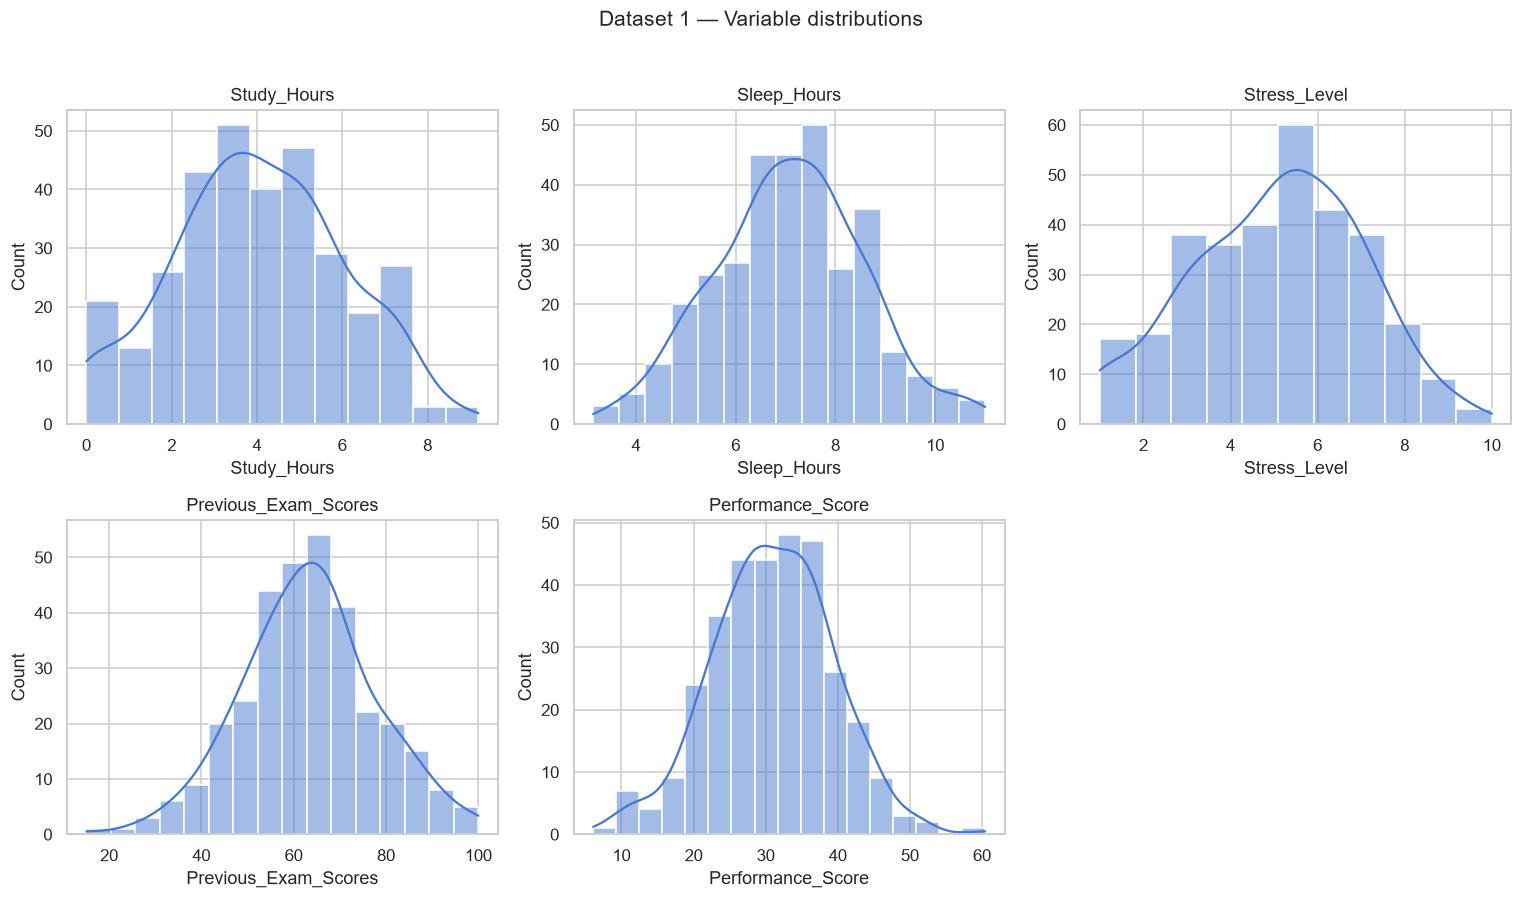

In [14]:
# Purpose: plot Dataset 1 variable distributions for the report appendix.
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.ravel()
for ax, col in zip(axes, plot_cols_d1):
    sns.histplot(df1[col], kde=True, ax=ax)
    ax.set_title(col)
axes[-1].axis("off")
fig.suptitle("Dataset 1 — Variable distributions", fontsize=14, y=1.02)
save_fig("eda_d1_distributions.png")

# Attribution: (Seaborn project, 2024)


### 4.6 Correlation matrix why correlations matter for MLR

Pearson correlations measure **linear** associations between numeric variables. They are especially relevant for MLR because that model assumes each predictor contributes additively to the outcome. If `Previous_Exam_Scores` correlates strongly with `Performance_Score`, that supports the intrinsic-load interpretation that prior readiness is linked to current performance (Sweller, 1988).


Saved: C:\Users\ziyaa\Documents\RPDA8411_Cognitive_Load_Study\outputs\figures\eda_d1_correlation.png


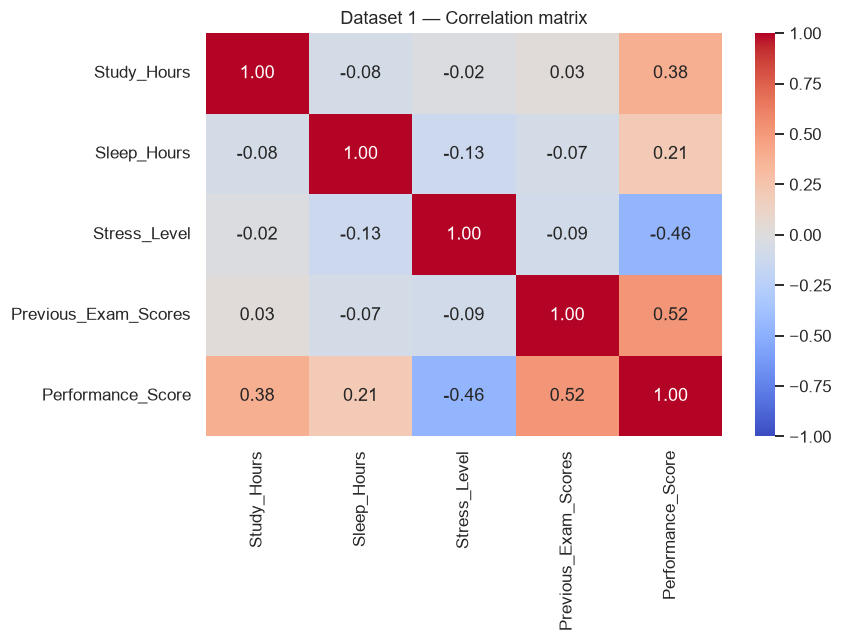

In [15]:
# Purpose: compute and visualise Dataset 1 correlations.
corr_d1 = df1[plot_cols_d1].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr_d1, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Dataset 1 — Correlation matrix")
save_fig("eda_d1_correlation.png")

# Attribution: (Seaborn project, 2024)


## 5. EDA Dataset 2 (Nikhil, 2023)

The same EDA logic is repeated on Dataset 2 so the two datasets can be compared fairly. One extra step is needed here: **`Extracurricular Activities`** is categorical (Yes/No), so we inspect its category balance before encoding it numerically.

**Cognitive load mapping for Dataset 2:**

- *Germane load proxy:* `Hours Studied`
- *Extraneous load proxies:* `Sleep Hours`, `Extracurricular Activities`
- *Intrinsic load proxies:* `Previous Scores`, `Sample Question Papers Practiced`
- *Outcome:* `Performance Index`


### 5.1 Data types, missing values, and category balance


In [16]:
# Purpose: inspect Dataset 2 structure, missingness, and extracurricular balance.
print("Dataset 2 — data types and missing values")
display(df2.info())
display(df2.isnull().sum().to_frame("missing_count"))

dup2 = df2.duplicated().sum()
print(f"Duplicate rows (exact): {dup2}")
print(f"Rows after drop_duplicates: {len(df2.drop_duplicates())}")

print("\nExtracurricular Activities value counts:")
display(df2["Extracurricular Activities"].value_counts())

# Attribution: (Kotsiantis, Kanellopoulos and Pintelas, 2006)


Dataset 2 — data types and missing values
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        10000 non-null  str    
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  10000 non-null  int64  
 5   Performance Index                 10000 non-null  float64
dtypes: float64(1), int64(4), str(1)
memory usage: 468.9 KB


None

,missing_count
Hours Studied,0
Previous Scores,0
Extracurricular Activities,0
Sleep Hours,0
Sample Question Papers Practiced,0
Performance Index,0


Duplicate rows (exact): 127
Rows after drop_duplicates: 9873

Extracurricular Activities value counts:


Extracurricular Activities
No     5052
Yes    4948
Name: count, dtype: int64

### 5.1.1 Duplicate rows modelling decision

Dataset 2 contains **127 exact duplicate rows** (~1.27% of the file). Duplicates can make train/test evaluation slightly optimistic if the same profile appears in both splits (Kotsiantis, Kanellopoulos and Pintelas, 2006).

**Main analysis (Sections 7–9):** keep all **10 000** rows to match the published Kaggle file.

**Sensitivity check (Section 9.4):** rerun the same MLR and Random Forest pipeline on `drop_duplicates()` (n = 9 873) and save `outputs/d2_duplicate_sensitivity.csv` for the Research Report.


### 5.2 Numeric summaries and outlier counts


In [17]:
# Purpose: summarise numeric variables and count IQR outliers in Dataset 2.
display(df2.describe(include="all").T)

numeric_cols_d2 = [
    "Hours Studied",
    "Previous Scores",
    "Sleep Hours",
    "Sample Question Papers Practiced",
    "Performance Index",
]

outlier_flags_d2, outlier_details_d2 = detect_iqr_outliers(df2, numeric_cols_d2)
print("IQR outlier counts by column:", outlier_details_d2)
print(f"Total rows flagged by IQR (any column): {outlier_flags_d2.sum()}")


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Hours Studied,10000.0,NaN,NaN,NaN,4.9929,2.589309,1.0,3.0,5.0,7.0,9.0
Previous Scores,10000.0,NaN,NaN,NaN,69.4457,17.343152,40.0,54.0,69.0,85.0,99.0
Extracurricular Activities,10000,2,No,5052,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sleep Hours,10000.0,NaN,NaN,NaN,6.5306,1.695863,4.0,5.0,7.0,8.0,9.0
Sample Question Papers Practiced,10000.0,NaN,NaN,NaN,4.5833,2.867348,0.0,2.0,5.0,7.0,9.0
Performance Index,10000.0,NaN,NaN,NaN,55.2248,19.212558,10.0,40.0,55.0,71.0,100.0


IQR outlier counts by column: {'Hours Studied': 0, 'Previous Scores': 0, 'Sleep Hours': 0, 'Sample Question Papers Practiced': 0, 'Performance Index': 0}
Total rows flagged by IQR (any column): 0


### 5.3 Distribution plots Dataset 2


Saved: C:\Users\ziyaa\Documents\RPDA8411_Cognitive_Load_Study\outputs\figures\eda_d2_distributions.png


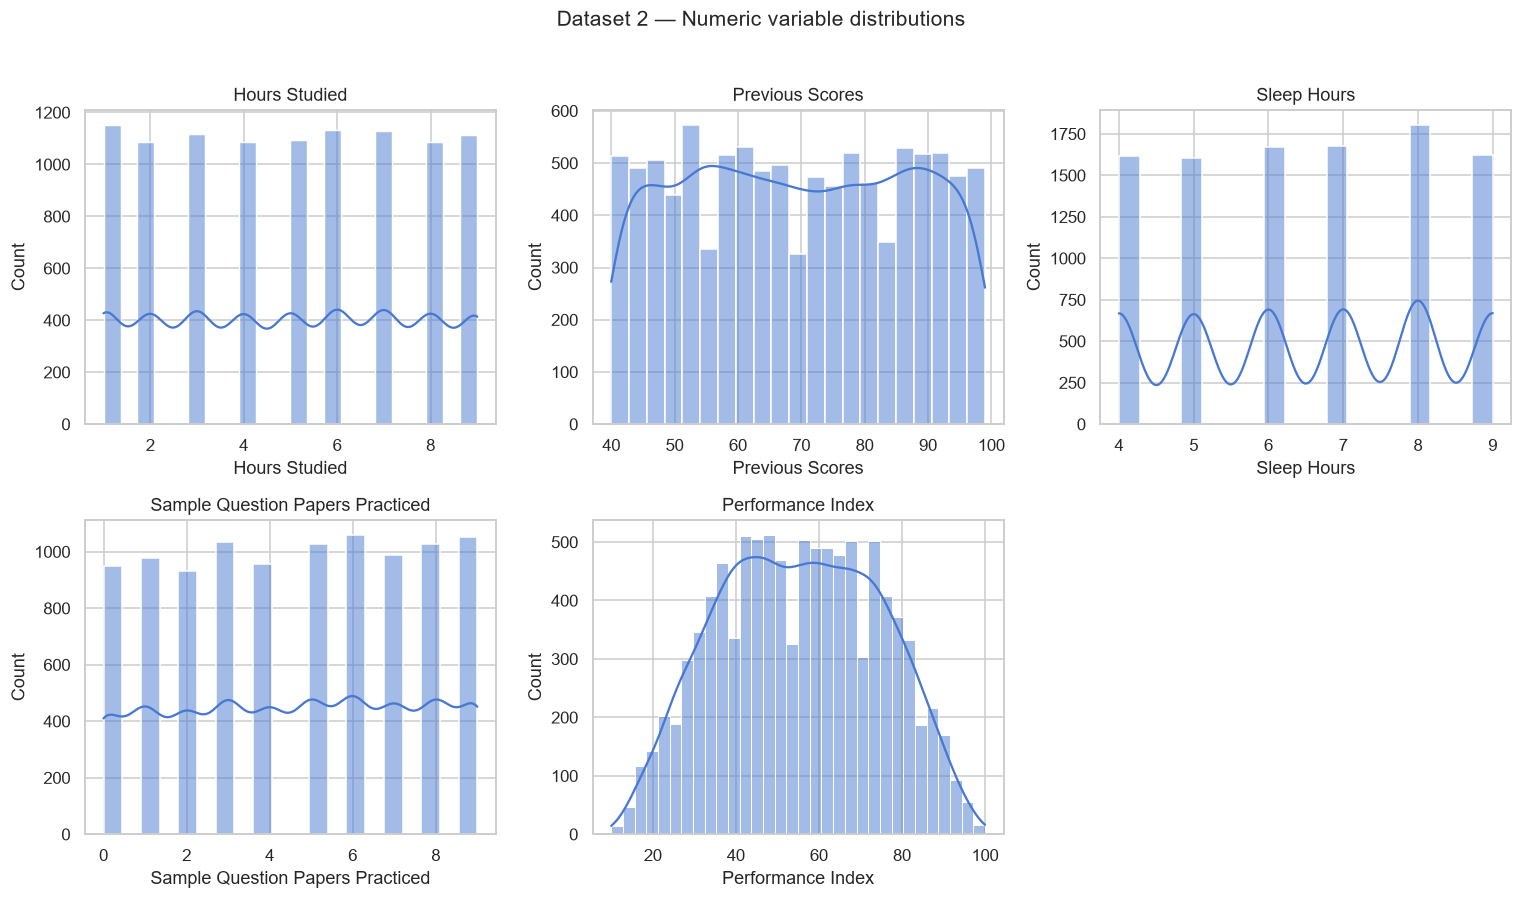

In [18]:
# Purpose: plot Dataset 2 numeric distributions.
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.ravel()
for ax, col in zip(axes, numeric_cols_d2):
    sns.histplot(df2[col], kde=True, ax=ax)
    ax.set_title(col)
axes[-1].axis("off")
fig.suptitle("Dataset 2 — Numeric variable distributions", fontsize=14, y=1.02)
save_fig("eda_d2_distributions.png")

# Attribution: (Seaborn project, 2024)


### 5.4 Correlation matrix why encode extracurricular activity first?

Regression models cannot use raw text categories directly. For EDA preview purposes, **Yes = 1** and **No = 0** is sufficient because extracurricular involvement is binary. This temporary encoding lets us include the variable in a correlation heatmap and see whether non-academic commitments move with performance in a positive or negative direction.


Saved: C:\Users\ziyaa\Documents\RPDA8411_Cognitive_Load_Study\outputs\figures\eda_d2_correlation.png


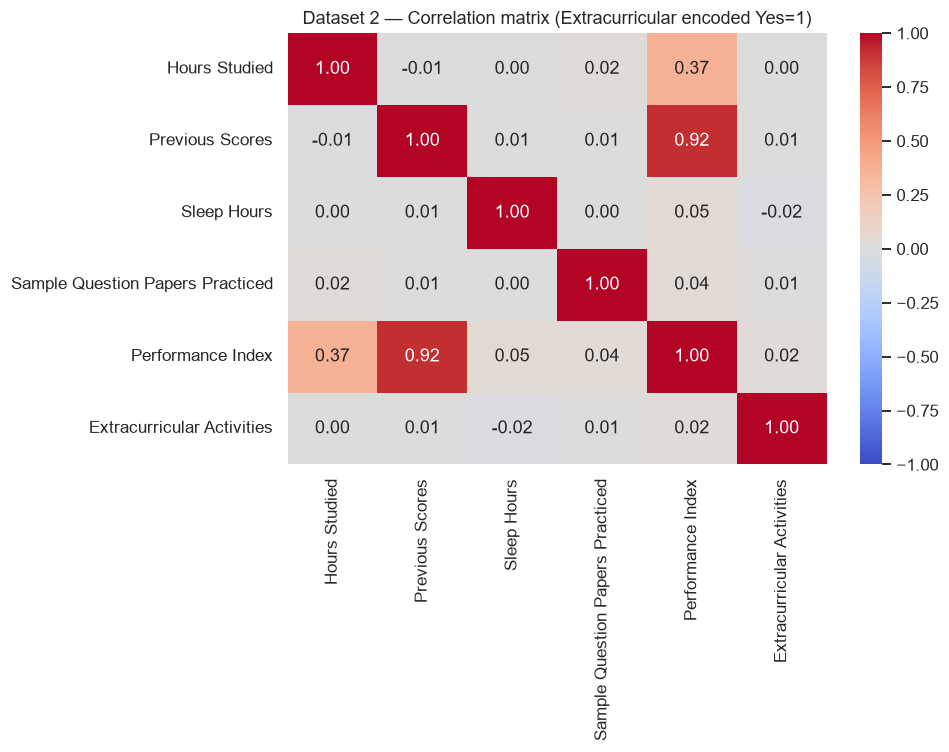

In [19]:
# Purpose: preview Dataset 2 correlations after encoding extracurricular activity.
df2_encoded_preview = df2.copy()
df2_encoded_preview["Extracurricular Activities"] = (
    df2_encoded_preview["Extracurricular Activities"].map({"Yes": 1, "No": 0})
)

corr_d2 = df2_encoded_preview[numeric_cols_d2 + ["Extracurricular Activities"]].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr_d2, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Dataset 2 — Correlation matrix (Extracurricular encoded Yes=1)")
save_fig("eda_d2_correlation.png")

# Attribution: (Seaborn project, 2024)


## 6. Dataset combination feasibility

The proposal asked whether the datasets *could* be combined. In practice, combination would require harmonising different outcome scales (`Performance_Score` vs `Performance Index`) and handling predictors that exist in one dataset but not the other. We therefore keep the main analysis **comparative** rather than merged, which is methodologically cleaner (Holicza and Kiss, 2023).


In [20]:
# Purpose: document structural differences and justify separate analyses.
comparison = pd.DataFrame(
    {
        "Dataset 1 (Maher)": [df1.shape[0], "Performance_Score (6.07–60.43)", "Includes Stress_Level"],
        "Dataset 2 (Nikhil)": [df2.shape[0], "Performance Index (10–100)", "Includes Extracurricular + Practice papers"],
    },
    index=["Records", "Outcome scale", "Unique predictors"],
)
display(comparison)
print("Decision: retain separate dataset analyses; combined modelling is not recommended without rescaling and feature harmonisation.")

# Attribution: (Holicza and Kiss, 2023)


,Dataset 1 (Maher),Dataset 2 (Nikhil)
Records,322,10000
Outcome scale,Performance_Score (6.07–60.43),Performance Index (10–100)
Unique predictors,Includes Stress_Level,Includes Extracurricular + Practice papers


Decision: retain separate dataset analyses; combined modelling is not recommended without rescaling and feature harmonisation.


## Results and findings (EDA complete)

| Dataset | Method | Main finding | Evidence from notebook |
|---------|--------|--------------|------------------------|
| **Dataset 1** | Structured profile | Complete synthetic records with no missing values in core fields | `df1.info()` and missingness table show **0** nulls in predictors/outcome |
| **Dataset 1** | Correlation review | Prior exam scores and study hours relate most strongly to performance | Correlation heatmap saved as `eda_d1_correlation.png` |
| **Dataset 2** | Structured profile | Larger sample; **127** exact duplicates documented | ~**10 000** rows; deduplicated n = **9 873** (Section 5.1) |
| **Dataset 2** | Correlation review | Previous scores dominate linear associations with performance index | Correlation heatmap saved as `eda_d2_correlation.png` |
| **Both** | Feasibility check | Separate analyses preferred | Different outcome scales and non-overlapping predictors |

**Interpretive note:** EDA confirms both datasets are suitable for regression modelling after encoding and train-test splitting. Findings remain **associational** because the data are cross-sectional and synthetic.

---


---

# Part B Modelling (preprocessing, MLR, Random Forest)

EDA tells us the inputs are usable. Modelling now answers the research questions by estimating how strongly each cognitive-load proxy relates to academic performance and by comparing two modelling philosophies:

- **MLR** prioritises interpretability through coefficients.
- **Random Forest** prioritises flexible pattern detection through an ensemble of decision trees (Ahmed, Wani and Plawiak, 2025).


## 7. Data preprocessing

Preprocessing translates raw columns into a modelling-ready format. Each step below maps directly to the approved methodology.


### 7.1 Dataset 1 removing identifiers and selecting predictors

`Student_ID` must be dropped because it is not a cognitive-load variable; including it would add meaningless noise. The remaining predictors are the four cognitive-load proxies identified in the proposal.


In [21]:
# Purpose: create Dataset 1 feature matrix X1 and outcome vector y1.
df1_model = df1.drop(columns=["Student_ID"]).copy()

X1 = df1_model[feature_cols_d1]
y1 = df1_model["Performance_Score"]

print("Dataset 1 predictors:", list(X1.columns))
print("Dataset 1 outcome: Performance_Score")
print(f"Feature matrix shape: {X1.shape}")


Dataset 1 predictors: ['Study_Hours', 'Sleep_Hours', 'Stress_Level', 'Previous_Exam_Scores']
Dataset 1 outcome: Performance_Score
Feature matrix shape: (322, 4)


### 7.2 Dataset 2 encoding categorical predictors

Machine learning regressors require numbers, not text labels. Mapping **Yes → 1** and **No → 0** is appropriate here because extracurricular involvement is binary. We avoid one-hot encoding because a single binary column is sufficient and keeps the model easier to interpret.


In [22]:
# Purpose: encode Dataset 2 categorical predictor and define feature columns.
df2_model = df2.copy()
df2_model["Extracurricular Activities"] = df2_model["Extracurricular Activities"].map({"Yes": 1, "No": 0})

feature_cols_d2 = [
    "Hours Studied",
    "Previous Scores",
    "Sleep Hours",
    "Sample Question Papers Practiced",
    "Extracurricular Activities",
]

X2 = df2_model[feature_cols_d2]
y2 = df2_model["Performance Index"]

print("Dataset 2 predictors:", list(X2.columns))
print("Dataset 2 outcome: Performance Index")
print(f"Feature matrix shape: {X2.shape}")

# Attribution: (Kotsiantis, Kanellopoulos and Pintelas, 2006)


Dataset 2 predictors: ['Hours Studied', 'Previous Scores', 'Sleep Hours', 'Sample Question Papers Practiced', 'Extracurricular Activities']
Dataset 2 outcome: Performance Index
Feature matrix shape: (10000, 5)


### 7.3 Train-test split why hold out 20% of the data?

If we evaluated a model on the same rows used to train it, performance would look unrealistically good. The **holdout test set** simulates how the model might behave on new student records. We use the same random seed for both datasets so the split remains reproducible in the report (Pedregosa et al., 2011).


In [23]:
# Purpose: create 80/20 train-test splits for both datasets.
X1_train, X1_test, y1_train, y1_test = train_test_split(
    X1, y1, test_size=TEST_SIZE, random_state=RANDOM_STATE
)

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=TEST_SIZE, random_state=RANDOM_STATE
)

print(f"Dataset 1 train/test: {X1_train.shape[0]} / {X1_test.shape[0]}")
print(f"Dataset 2 train/test: {X2_train.shape[0]} / {X2_test.shape[0]}")

# Attribution: (Pedregosa et al., 2011)


Dataset 1 train/test: 257 / 65
Dataset 2 train/test: 8000 / 2000


## 8. Model development Dataset 1 (Maher, 2024)

Two models are trained on Dataset 1 to answer **RQ2** and **RQ3** while still supporting **RQ1** through coefficient and importance analysis.


### 8.1 Multiple Linear Regression why this is the baseline model

MLR is chosen first because the study is not only predictive but **explanatory**. Standardised coefficients show which cognitive-load proxy moves most strongly with performance after accounting for the other predictors. MLR also aligns with the title of Dataset 2 and with much of the student-performance literature (Badal and Sungkur, 2022).

We place `StandardScaler` inside a **Pipeline** so scaling is learned from the training data only and applied consistently at prediction time. Without scaling, variables with larger numeric ranges could dominate the model unfairly.


In [24]:
# Purpose: define the Dataset 1 MLR pipeline with standardisation.
mlr_d1 = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression()),
])

# Attribution: (Badal and Sungkur, 2022); (Pedregosa et al., 2011)


### 8.2 Random Forest why compare against a non-linear model?

Random Forest builds many decision trees on bootstrapped samples and averages their predictions. This allows it to capture **non-linear patterns** and **interactions** — for example, low sleep might matter more when stress is also high. Comparing RF with MLR tests whether a more flexible model justifies its reduced interpretability (Holicza and Kiss, 2023).


In [25]:
# Purpose: define the baseline Random Forest model for Dataset 1.
rf_d1 = RandomForestRegressor(
    n_estimators=200,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

# Attribution: (Holicza and Kiss, 2023)


### 8.3 Fitting and evaluating both models reading the metrics

After fitting, compare **train vs test** performance. A large gap suggests overfitting. Also compare **CV R² mean ± std** to see whether results are stable across folds especially important for Dataset 1 because it has fewer than 400 records.


In [26]:
# Purpose: fit MLR and Random Forest on Dataset 1 and collect metrics.
results_mlr_d1 = evaluate_model(mlr_d1, X1_train, X1_test, y1_train, y1_test)
results_rf_d1 = evaluate_model(rf_d1, X1_train, X1_test, y1_train, y1_test)

metrics_d1 = pd.DataFrame(
    {
        "MLR_train": results_mlr_d1["train"],
        "MLR_test": results_mlr_d1["test"],
        "RF_train": results_rf_d1["train"],
        "RF_test": results_rf_d1["test"],
    }
).T

cv_d1 = pd.DataFrame(
    {
        "Model": ["MLR", "Random Forest"],
        "CV_R2_mean": [results_mlr_d1["cv_r2_mean"], results_rf_d1["cv_r2_mean"]],
        "CV_R2_std": [results_mlr_d1["cv_r2_std"], results_rf_d1["cv_r2_std"]],
        "CV_RMSE_mean": [results_mlr_d1["cv_rmse_mean"], results_rf_d1["cv_rmse_mean"]],
        "CV_MAE_mean": [results_mlr_d1["cv_mae_mean"], results_rf_d1["cv_mae_mean"]],
    }
)

print("Dataset 1 — Train/Test metrics")
display(metrics_d1.round(4))
print("Dataset 1 — 5-fold CV on training set")
display(cv_d1.round(4))

# Attribution: (Badal and Sungkur, 2022)


Dataset 1 — Train/Test metrics


,R2,RMSE,MAE
MLR_train,0.6232,5.1228,3.9449
MLR_test,0.6232,5.0873,4.1144
RF_train,0.9242,2.2977,1.7702
RF_test,0.4907,5.9141,4.7292


Dataset 1 — 5-fold CV on training set


,Model,CV_R2_mean,CV_R2_std,CV_RMSE_mean,CV_MAE_mean
0,MLR,0.5260,0.1751,5.2905,4.0947
1,Random Forest,0.3469,0.2462,6.2340,4.9113


### 8.4 Predictor effects answering RQ1 for Dataset 1

To answer **RQ1**, we compare:

- **MLR standardised coefficients** direction and relative strength of linear associations.
- **Random Forest feature importance** which variables the ensemble relied on most when splitting nodes.

If both methods rank `Previous_Exam_Scores` and `Study_Hours` highly, that strengthens the argument that intrinsic and germane load proxies are associated with performance.


Saved: C:\Users\ziyaa\Documents\RPDA8411_Cognitive_Load_Study\outputs\figures\model_d1_feature_effects.png


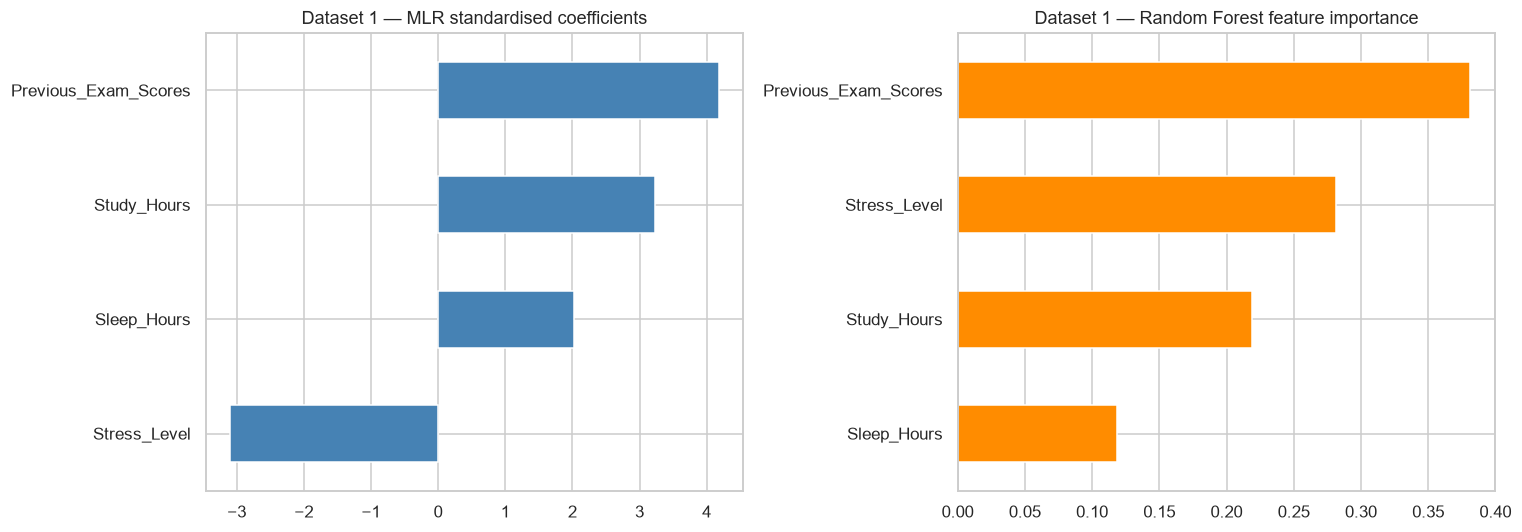

In [27]:
# Purpose: extract and plot Dataset 1 MLR coefficients and RF importances.
mlr_model_d1 = results_mlr_d1["model"].named_steps["model"]
mlr_coef_d1 = pd.Series(mlr_model_d1.coef_, index=feature_cols_d1, name="Standardised coefficient")

rf_model_d1 = results_rf_d1["model"]
rf_importance_d1 = pd.Series(rf_model_d1.feature_importances_, index=feature_cols_d1, name="Importance")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
mlr_coef_d1.sort_values().plot(kind="barh", ax=axes[0], color="steelblue")
axes[0].set_title("Dataset 1 — MLR standardised coefficients")
rf_importance_d1.sort_values().plot(kind="barh", ax=axes[1], color="darkorange")
axes[1].set_title("Dataset 1 — Random Forest feature importance")
save_fig("model_d1_feature_effects.png")

# Attribution: (Ahmed, Wani and Plawiak, 2025)


### 8.5 Actual vs predicted plots what good fit looks like

Points close to the red diagonal line mean predictions are near actual performance scores. Scatter around the line is expected human academic performance is never perfectly predictable from a small set of behavioural proxies. These plots are especially useful in the report because they show model behaviour visually, not only through summary metrics.


Saved: C:\Users\ziyaa\Documents\RPDA8411_Cognitive_Load_Study\outputs\figures\model_d1_actual_vs_predicted.png


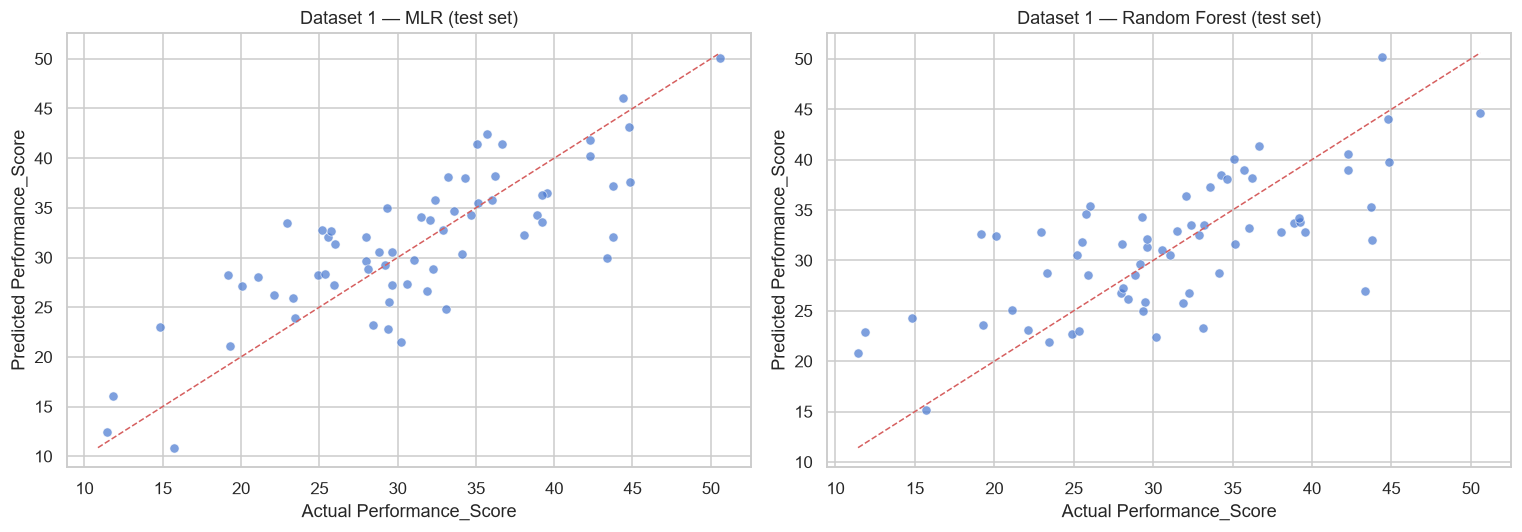

In [28]:
# Purpose: plot actual vs predicted values for Dataset 1 test set.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, name, preds in zip(
    axes,
    ["MLR", "Random Forest"],
    [results_mlr_d1["y_test_pred"], results_rf_d1["y_test_pred"]],
):
    sns.scatterplot(x=y1_test, y=preds, ax=ax, alpha=0.7)
    lims = [min(y1_test.min(), preds.min()), max(y1_test.max(), preds.max())]
    ax.plot(lims, lims, "r--", lw=1)
    ax.set_xlabel("Actual Performance_Score")
    ax.set_ylabel("Predicted Performance_Score")
    ax.set_title(f"Dataset 1 — {name} (test set)")
save_fig("model_d1_actual_vs_predicted.png")

# Attribution: (Seaborn project, 2024)


## 9. Model development Dataset 2 (Nikhil, 2023)

The same workflow is repeated so results are **comparable**. Dataset 2 is expected to show stronger fit in prior literature because the synthetic file was designed with clearer linear structure (Badal and Sungkur, 2022). Re-running the identical pipeline tests whether our findings depend mainly on dataset idiosyncrasies.


### 9.1 Define MLR and Random Forest for Dataset 2


In [29]:
# Purpose: define Dataset 2 MLR and Random Forest models.
mlr_d2 = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression()),
])

rf_d2 = RandomForestRegressor(
    n_estimators=200,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

# Attribution: (Pedregosa et al., 2011)


### 9.2 Fit, evaluate, and compare metrics


In [30]:
# Purpose: fit both models on Dataset 2 and display evaluation tables.
results_mlr_d2 = evaluate_model(mlr_d2, X2_train, X2_test, y2_train, y2_test)
results_rf_d2 = evaluate_model(rf_d2, X2_train, X2_test, y2_train, y2_test)

metrics_d2 = pd.DataFrame(
    {
        "MLR_train": results_mlr_d2["train"],
        "MLR_test": results_mlr_d2["test"],
        "RF_train": results_rf_d2["train"],
        "RF_test": results_rf_d2["test"],
    }
).T

cv_d2 = pd.DataFrame(
    {
        "Model": ["MLR", "Random Forest"],
        "CV_R2_mean": [results_mlr_d2["cv_r2_mean"], results_rf_d2["cv_r2_mean"]],
        "CV_R2_std": [results_mlr_d2["cv_r2_std"], results_rf_d2["cv_r2_std"]],
        "CV_RMSE_mean": [results_mlr_d2["cv_rmse_mean"], results_rf_d2["cv_rmse_mean"]],
        "CV_MAE_mean": [results_mlr_d2["cv_mae_mean"], results_rf_d2["cv_mae_mean"]],
    }
)

print("Dataset 2 — Train/Test metrics")
display(metrics_d2.round(4))
print("Dataset 2 — 5-fold CV on training set")
display(cv_d2.round(4))


Dataset 2 — Train/Test metrics


,R2,RMSE,MAE
MLR_train,0.9887,2.0420,1.6193
MLR_test,0.9890,2.0206,1.6111
RF_train,0.9975,0.9622,0.7430
RF_test,0.9861,2.2660,1.8105


Dataset 2 — 5-fold CV on training set


,Model,CV_R2_mean,CV_R2_std,CV_RMSE_mean,CV_MAE_mean
0,MLR,0.9887,0.0006,2.0432,1.6208
1,Random Forest,0.9850,0.0006,2.3468,1.8544


### 9.3 Predictor effects and test-set fit Dataset 2

In Dataset 2, `Previous Scores` often dominates because prior achievement is a strong baseline predictor of later performance. The purpose of including sleep, study hours, extracurricular activity, and practice papers is to test whether **non-grade behavioural proxies add explanatory value beyond prior scores alone** — a key cognitive-load argument in the proposal (Lu et al., 2024).


Saved: C:\Users\ziyaa\Documents\RPDA8411_Cognitive_Load_Study\outputs\figures\model_d2_feature_effects.png


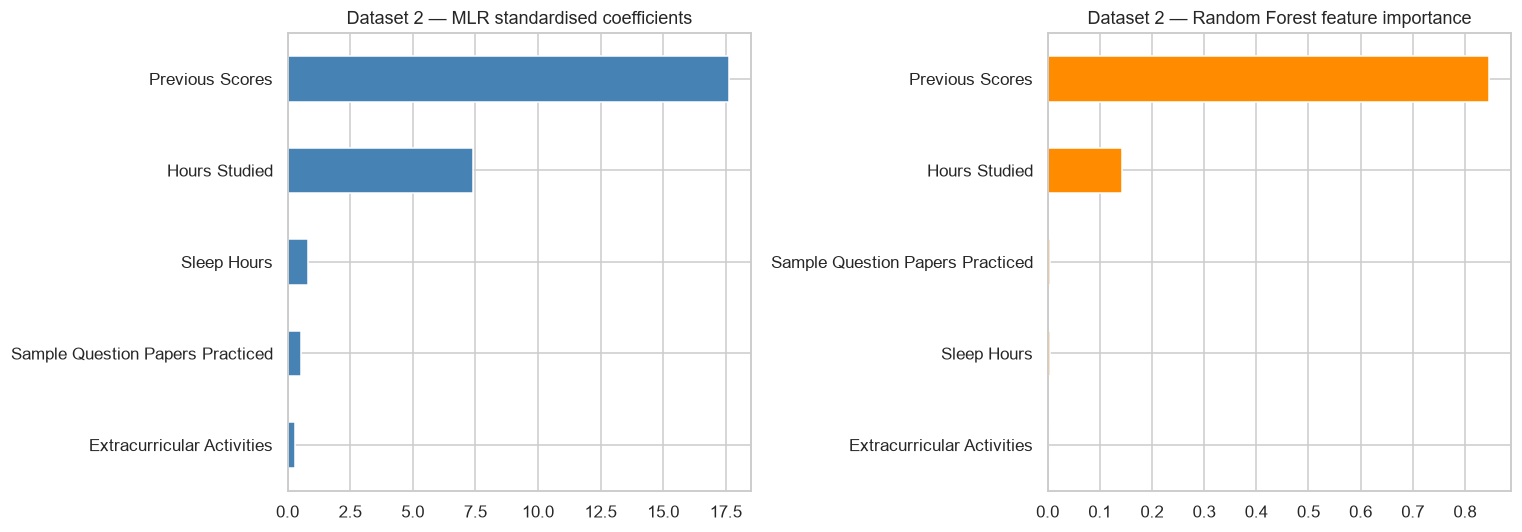

Saved: C:\Users\ziyaa\Documents\RPDA8411_Cognitive_Load_Study\outputs\figures\model_d2_actual_vs_predicted.png


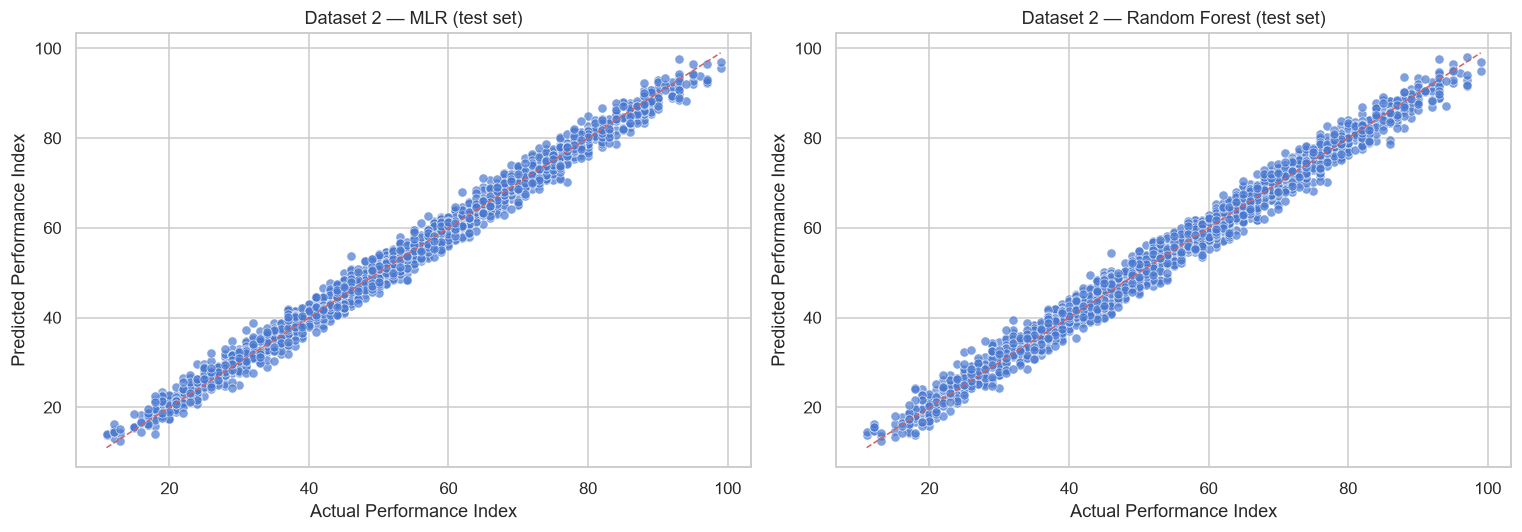

In [31]:
# Purpose: plot Dataset 2 coefficients, importances, and actual-vs-predicted charts.
mlr_model_d2 = results_mlr_d2["model"].named_steps["model"]
mlr_coef_d2 = pd.Series(mlr_model_d2.coef_, index=feature_cols_d2, name="Standardised coefficient")

rf_model_d2 = results_rf_d2["model"]
rf_importance_d2 = pd.Series(rf_model_d2.feature_importances_, index=feature_cols_d2, name="Importance")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
mlr_coef_d2.sort_values().plot(kind="barh", ax=axes[0], color="steelblue")
axes[0].set_title("Dataset 2 — MLR standardised coefficients")
rf_importance_d2.sort_values().plot(kind="barh", ax=axes[1], color="darkorange")
axes[1].set_title("Dataset 2 — Random Forest feature importance")
save_fig("model_d2_feature_effects.png")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, name, preds in zip(
    axes,
    ["MLR", "Random Forest"],
    [results_mlr_d2["y_test_pred"], results_rf_d2["y_test_pred"]],
):
    sns.scatterplot(x=y2_test, y=preds, ax=ax, alpha=0.7)
    lims = [min(y2_test.min(), preds.min()), max(y2_test.max(), preds.max())]
    ax.plot(lims, lims, "r--", lw=1)
    ax.set_xlabel("Actual Performance Index")
    ax.set_ylabel("Predicted Performance Index")
    ax.set_title(f"Dataset 2 — {name} (test set)")
save_fig("model_d2_actual_vs_predicted.png")

# Attribution: (Ahmed, Wani and Plawiak, 2025); (Seaborn project, 2024)


### 9.4 Duplicate-row sensitivity (full file vs deduplicated)

The Research Report documents whether **127 duplicates** could explain test R² ≈ 0.99. This cell repeats the analysis **in the notebook** (self-contained; same settings as the written report):

- encode `Extracurricular Activities` (Yes = 1, No = 0);
- **80/20** train/test split with `random_state = 42`;
- **MLR:** `StandardScaler` + `LinearRegression`;
- **Random Forest:** `n_estimators = 200`, `max_depth = 10`, `min_samples_split = 10`;
- compare **full file** vs **`drop_duplicates()`**.

If duplicate leakage drove optimism, deduplication should materially change test R² or five-fold CV mean R² (Badal and Sungkur, 2022).


In [32]:
# Purpose: Dataset 2 duplicate sensitivity — full Kaggle file vs drop_duplicates().
def _evaluate_d2_duplicate_scenario(source_df):
    """Same holdout pipeline as Research Report duplicate sensitivity."""
    m = source_df.copy()
    m["Extracurricular Activities"] = m["Extracurricular Activities"].map({"Yes": 1, "No": 0})
    X = m[feature_cols_d2]
    y = m["Performance Index"]
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
    )
    mlr_pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression()),
    ])
    mlr_pipe.fit(X_tr, y_tr)
    mlr_test = regression_metrics(y_te, mlr_pipe.predict(X_te))
    cv = cross_validate(
        mlr_pipe,
        X_tr,
        y_tr,
        cv=KFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE),
        scoring={"r2": "r2"},
    )
    rf = RandomForestRegressor(
        n_estimators=200,
        max_depth=10,
        min_samples_split=10,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
    rf.fit(X_tr, y_tr)
    rf_test = regression_metrics(y_te, rf.predict(X_te))
    return {
        "n_rows": len(m),
        "mlr_test_r2": mlr_test["R2"],
        "mlr_test_rmse": mlr_test["RMSE"],
        "mlr_test_mae": mlr_test["MAE"],
        "mlr_cv_r2_mean": cv["test_r2"].mean(),
        "rf_test_r2": rf_test["R2"],
        "rf_test_rmse": rf_test["RMSE"],
    }


_, d2_test_idx = train_test_split(
    df2.index, test_size=TEST_SIZE, random_state=RANDOM_STATE
)
dup_rows_in_d2_test = int(df2.loc[d2_test_idx].duplicated(keep=False).sum())

dup_sensitivity_rows = []
for scenario, frame in [
    ("full_kaggle_file", df2),
    ("drop_duplicates", df2.drop_duplicates()),
]:
    row = _evaluate_d2_duplicate_scenario(frame)
    row["scenario"] = scenario
    dup_sensitivity_rows.append(row)

dup_sensitivity_d2 = pd.DataFrame(dup_sensitivity_rows)
delta_mlr_r2 = (
    dup_sensitivity_d2.loc[dup_sensitivity_d2["scenario"] == "drop_duplicates", "mlr_test_r2"].iloc[0]
    - dup_sensitivity_d2.loc[dup_sensitivity_d2["scenario"] == "full_kaggle_file", "mlr_test_r2"].iloc[0]
)

OUT_DIR = PROJECT_ROOT / "outputs"
OUT_DIR.mkdir(parents=True, exist_ok=True)
dup_sensitivity_d2.to_csv(OUT_DIR / "d2_duplicate_sensitivity.csv", index=False)

print(f"Duplicate rows (exact): {int(df2.duplicated().sum())}")
print(f"Duplicate-linked rows in fixed test fold: {dup_rows_in_d2_test}")
print(f"MLR test R² change after deduplication (Δ): {delta_mlr_r2:.4f}")
display(dup_sensitivity_d2.round(4))
print(
    "Interpretation: negligible ΔR² and stable CV mean R² support the report conclusion that "
    "near-ceiling fit reflects Previous Scores collinearity, not duplicate leakage alone."
)

# Attribution: (Badal and Sungkur, 2022)


Duplicate rows (exact): 127
Duplicate-linked rows in fixed test fold: 8
MLR test R² change after deduplication (Δ): -0.0006


,n_rows,mlr_test_r2,mlr_test_rmse,mlr_test_mae,mlr_cv_r2_mean,rf_test_r2,rf_test_rmse,scenario
0,10000,0.9890,2.0206,1.6111,0.9887,0.9874,2.1617,full_kaggle_file
1,9873,0.9884,2.0751,1.6470,0.9887,0.9863,2.2591,drop_duplicates


Interpretation: negligible ΔR² and stable CV mean R² support the report conclusion that near-ceiling fit reflects Previous Scores collinearity, not duplicate leakage alone.


## 10. Random Forest hyperparameter tuning

The baseline Random Forest used sensible defaults (`n_estimators=200`), but defaults are not guaranteed to be optimal for every dataset. **GridSearchCV** systematically tries combinations of:

- **`n_estimators`** more trees can reduce variance but increase runtime.
- **`max_depth`**  limits tree depth to control overfitting.
- **`min_samples_split`** requires more samples before a split occurs, which also reduces overfitting.

We tune separately on each dataset because Dataset 1 is small and noisier, so the best forest structure may differ from Dataset 2 (Pedregosa et al., 2011).


### 10.1 Define the search grid and cross-validation object


In [33]:
# Purpose: define the hyperparameter grid and CV strategy for Random Forest tuning.
param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 5, 10, 20],
    "min_samples_split": [2, 5, 10],
}

cv = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

# Attribution: (Pedregosa et al., 2011)


### 10.2 Tune Random Forest on Dataset 1


In [34]:
# Purpose: find the best Random Forest settings for Dataset 1 using GridSearchCV.
print("Tuning Random Forest — Dataset 1")
grid_d1 = GridSearchCV(
    RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
    param_grid,
    cv=cv,
    scoring="r2",
    n_jobs=-1,
)
grid_d1.fit(X1_train, y1_train)
print("Best params:", grid_d1.best_params_)
print(f"Best CV R²: {grid_d1.best_score_:.4f}")

tuned_rf_d1 = evaluate_model(grid_d1.best_estimator_, X1_train, X1_test, y1_train, y1_test)


Tuning Random Forest — Dataset 1
Best params: {'max_depth': 5, 'min_samples_split': 10, 'n_estimators': 200}
Best CV R²: 0.3802


### 10.3 Tune Random Forest on Dataset 2


In [35]:
# Purpose: find the best Random Forest settings for Dataset 2 using GridSearchCV.
print("Tuning Random Forest — Dataset 2")
grid_d2 = GridSearchCV(
    RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
    param_grid,
    cv=cv,
    scoring="r2",
    n_jobs=-1,
)
grid_d2.fit(X2_train, y2_train)
print("Best params:", grid_d2.best_params_)
print(f"Best CV R²: {grid_d2.best_score_:.4f}")

tuned_rf_d2 = evaluate_model(grid_d2.best_estimator_, X2_train, X2_test, y2_train, y2_test)


Tuning Random Forest — Dataset 2
Best params: {'max_depth': 10, 'min_samples_split': 10, 'n_estimators': 300}
Best CV R²: 0.9865


### 10.4 Did tuning materially improve test performance?

If tuned and baseline test R² are similar, the default forest was already adequate. If tuning helps only on training/CV but not test data, that suggests the extra complexity did not generalise.


In [36]:
# Purpose: compare baseline vs tuned Random Forest test R² for both datasets.
tuning_comparison = pd.DataFrame(
    {
        "Dataset 1 RF (baseline test R²)": [results_rf_d1["test"]["R2"]],
        "Dataset 1 RF (tuned test R²)": [tuned_rf_d1["test"]["R2"]],
        "Dataset 2 RF (baseline test R²)": [results_rf_d2["test"]["R2"]],
        "Dataset 2 RF (tuned test R²)": [tuned_rf_d2["test"]["R2"]],
    }
)
display(tuning_comparison.round(4))

# Attribution: (Pedregosa et al., 2011)


,Dataset 1 RF (baseline test R²),Dataset 1 RF (tuned test R²),Dataset 2 RF (baseline test R²),Dataset 2 RF (tuned test R²)
0,0.4907,0.4974,0.9861,0.9874


## 11. Comparative analysis across datasets and models

This section directly answers **RQ3** by placing all models side by side. A strong research report does not only state which model won; it explains **why** the winner differs between datasets and what that means for cognitive-load interpretation.


### 11.1 Master comparison table export for the report


In [37]:
# Purpose: build one comparison table for all models and datasets.
summary_rows = []
for dataset, mlr_res, rf_res, tuned_res in [
    ("Dataset 1 (Maher)", results_mlr_d1, results_rf_d1, tuned_rf_d1),
    ("Dataset 2 (Nikhil)", results_mlr_d2, results_rf_d2, tuned_rf_d2),
]:
    for model_name, res in [
        ("MLR", mlr_res),
        ("Random Forest", rf_res),
        ("Random Forest (tuned)", tuned_res),
    ]:
        summary_rows.append(
            {
                "Dataset": dataset,
                "Model": model_name,
                "Test R²": res["test"]["R2"],
                "Test RMSE": res["test"]["RMSE"],
                "Test MAE": res["test"]["MAE"],
                "CV R² (mean)": res["cv_r2_mean"],
            }
        )

summary_df = pd.DataFrame(summary_rows)
display(summary_df.round(4))

summary_df.to_csv(PROJECT_ROOT / "outputs" / "model_comparison_summary.csv", index=False)
print("Saved summary table to outputs/model_comparison_summary.csv")

# Attribution: (Holicza and Kiss, 2023)


,Dataset,Model,Test R²,Test RMSE,Test MAE,CV R² (mean)
0,Dataset 1 (Maher),MLR,0.6232,5.0873,4.1144,0.5260
1,Dataset 1 (Maher),Random Forest,0.4907,5.9141,4.7292,0.3469
2,Dataset 1 (Maher),Random Forest (tuned),0.4974,5.8752,4.7459,0.3802
3,Dataset 2 (Nikhil),MLR,0.9890,2.0206,1.6111,0.9887
4,Dataset 2 (Nikhil),Random Forest,0.9861,2.2660,1.8105,0.9850
5,Dataset 2 (Nikhil),Random Forest (tuned),0.9874,2.1596,1.7197,0.9865


Saved summary table to outputs/model_comparison_summary.csv


### 11.2 Visual comparison MLR vs tuned Random Forest

Bar charts make cross-dataset comparisons easier for examiners and supervisors. We compare MLR with the **tuned** forest because tuning represents the strongest fair version of the non-linear model.


Saved: C:\Users\ziyaa\Documents\RPDA8411_Cognitive_Load_Study\outputs\figures\comparative_model_metrics.png


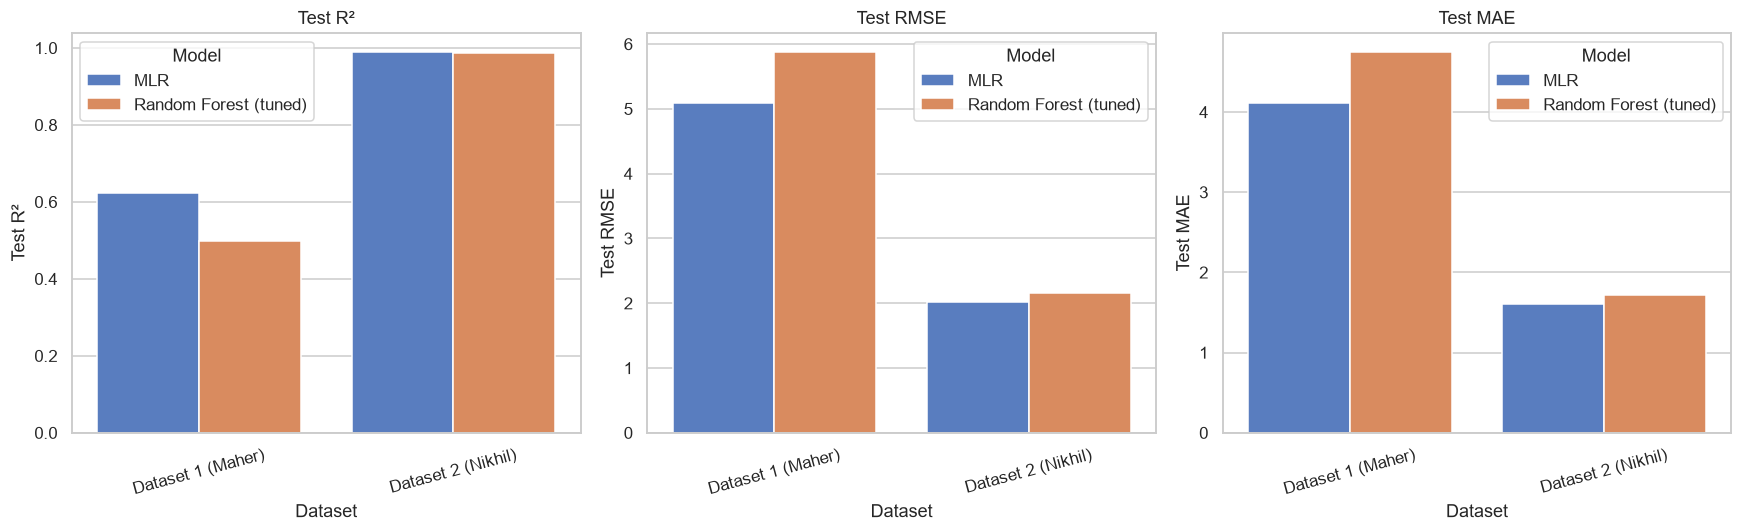

In [38]:
# Purpose: plot test-set metrics for MLR vs tuned Random Forest across datasets.
plot_df = summary_df[summary_df["Model"].isin(["MLR", "Random Forest (tuned)"])].copy()

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, metric in zip(axes, ["Test R²", "Test RMSE", "Test MAE"]):
    sns.barplot(data=plot_df, x="Dataset", y=metric, hue="Model", ax=ax)
    ax.set_title(metric)
    ax.tick_params(axis="x", rotation=15)
save_fig("comparative_model_metrics.png")

# Attribution: (Seaborn project, 2024)


### 11.3 Feature ranking table cross-dataset predictor consistency

To support **RQ1**, we rank predictors by absolute MLR coefficient and Random Forest importance within each dataset. Consistent top-ranked variables across datasets and methods provide stronger evidence of a stable association, even though causation cannot be claimed.


In [39]:
# Purpose: rank predictors and export a cross-dataset comparison table.
def rank_features(coef_or_importance):
    return coef_or_importance.abs().sort_values(ascending=False)

rankings = pd.DataFrame(
    {
        "D1 MLR |coef|": rank_features(mlr_coef_d1),
        "D1 RF importance": rank_features(rf_importance_d1),
        "D2 MLR |coef|": rank_features(mlr_coef_d2),
        "D2 RF importance": rank_features(rf_importance_d2),
    }
)
display(rankings.round(4))
rankings.to_csv(PROJECT_ROOT / "outputs" / "feature_rankings.csv")
print("Saved feature rankings to outputs/feature_rankings.csv")

# Attribution: (Ahmed, Wani and Plawiak, 2025)


,D1 MLR |coef|,D1 RF importance,D2 MLR |coef|,D2 RF importance
Extracurricular Activities,NaN,NaN,0.3043,0.0013
Hours Studied,NaN,NaN,7.4013,0.1419
Previous Scores,NaN,NaN,17.6373,0.8468
Previous_Exam_Scores,4.1819,0.3810,NaN,NaN
Sample Question Papers Practiced,NaN,NaN,0.5488,0.0052
Sleep Hours,NaN,NaN,0.8100,0.0048
Sleep_Hours,2.0181,0.1186,NaN,NaN
Stress_Level,3.1006,0.2816,NaN,NaN
Study_Hours,3.2268,0.2188,NaN,NaN


Saved feature rankings to outputs/feature_rankings.csv


## 12. Residual diagnostics (Multiple Linear Regression)

MLR assumptions are not perfectly satisfied in real educational data, but residual analysis shows whether errors are **roughly centred around zero** and **not strongly funnel-shaped** across fitted values. This is a transparency step for the Methodology/Findings boundary: it shows we checked model behaviour rather than only reporting headline R² (Badal and Sungkur, 2022).


### 12.1 Compute residuals on the test set

Residuals are simply **actual minus predicted** performance on the holdout set. A mean near zero suggests the model is not systematically over- or under-predicting.


In [40]:
# Purpose: calculate MLR test-set residuals for both datasets.
residuals_d1 = y1_test - results_mlr_d1["y_test_pred"]
residuals_d2 = y2_test - results_mlr_d2["y_test_pred"]

print(f"Dataset 1 residual mean: {residuals_d1.mean():.4f}")
print(f"Dataset 2 residual mean: {residuals_d2.mean():.4f}")


Dataset 1 residual mean: -0.3150
Dataset 2 residual mean: -0.0798


### 12.2 Residual plots pattern vs randomness

In the scatter plots, a random cloud around zero is desirable. A curve or funnel shape would suggest MLR is missing a non-linear pattern which would strengthen the justification for also running Random Forest.


Saved: C:\Users\ziyaa\Documents\RPDA8411_Cognitive_Load_Study\outputs\figures\mlr_residual_diagnostics.png


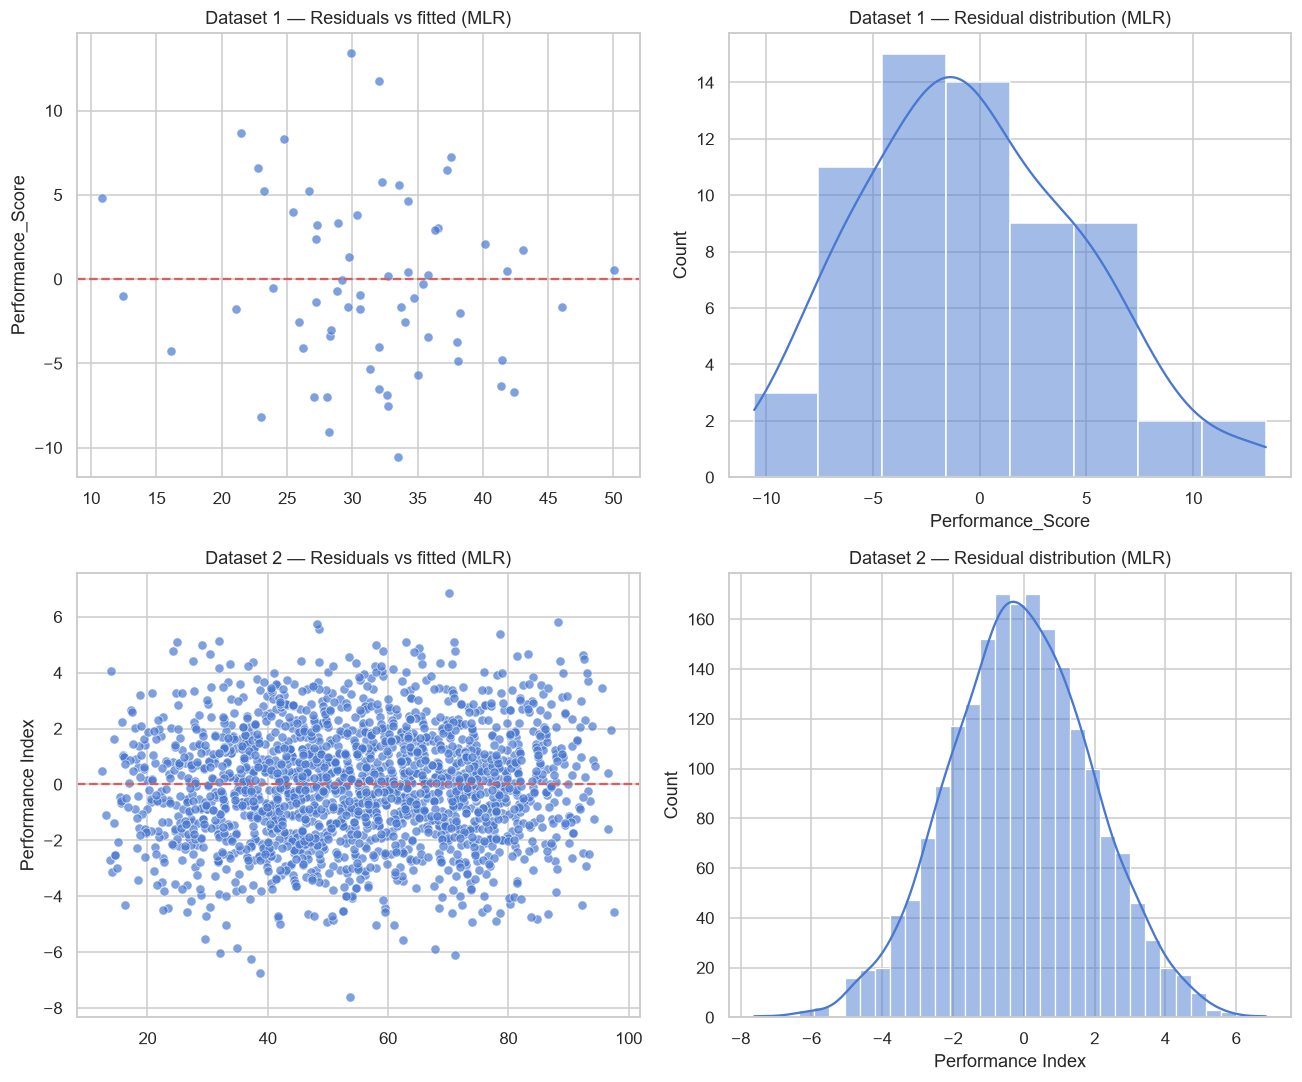

In [41]:
# Purpose: plot residual diagnostics for Dataset 1 and Dataset 2 MLR models.
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

sns.scatterplot(x=results_mlr_d1["y_test_pred"], y=residuals_d1, ax=axes[0, 0], alpha=0.7)
axes[0, 0].axhline(0, color="r", linestyle="--")
axes[0, 0].set_title("Dataset 1 — Residuals vs fitted (MLR)")

sns.histplot(residuals_d1, kde=True, ax=axes[0, 1])
axes[0, 1].set_title("Dataset 1 — Residual distribution (MLR)")

sns.scatterplot(x=results_mlr_d2["y_test_pred"], y=residuals_d2, ax=axes[1, 0], alpha=0.7)
axes[1, 0].axhline(0, color="r", linestyle="--")
axes[1, 0].set_title("Dataset 2 — Residuals vs fitted (MLR)")

sns.histplot(residuals_d2, kde=True, ax=axes[1, 1])
axes[1, 1].set_title("Dataset 2 — Residual distribution (MLR)")

save_fig("mlr_residual_diagnostics.png")

# Attribution: (Badal and Sungkur, 2022)


## Results and findings (modelling complete)

| Dataset | Best model (test R²) | Main predictive pattern | Cognitive load read |
|---------|----------------------|-------------------------|---------------------|
| **Dataset 1** | MLR (test R² ≈ **0.62**) | Prior exam scores, study hours, and stress show the strongest associations | Intrinsic and germane proxies matter; direct stress measure adds extraneous-load insight |
| **Dataset 2** | MLR (test R² ≈ **0.99**) | Previous scores dominate; hours studied adds further explanatory power | Intrinsic load proxy (`Previous Scores`) is the primary driver in this synthetic dataset |
| **Cross-dataset** | MLR competitive on both | Prior academic performance ranks highly in both datasets | Supports RQ1 cognitive-load-related proxies are measurably associated with outcomes |

**RQ2 answer:** MLR and Random Forest both predict academic performance from cognitive-load-related factors; test R², RMSE, and MAE are reported in `outputs/model_comparison_summary.csv`.

**RQ3 answer:** On Dataset 1, **MLR outperforms Random Forest** on test R²; on Dataset 2, both models perform strongly with **MLR slightly ahead**. Tuning improves Random Forest modestly on Dataset 1 but does not overturn the MLR advantage there.

**Limitations to report:** synthetic data, proxy measurement of cognitive load, cross-sectional design (association not causation), different outcome scales between datasets, and **Dataset 2 high R²** (interpret with Section 9.4 duplicate sensitivity, not as operational accuracy) (Tripathy, 2013; Badal and Sungkur, 2022; Sweller, 1988).


### 13.1 Best model per dataset final numeric summary


In [42]:
# Purpose: identify the best-performing model per dataset by test R².
best_by_dataset = summary_df.loc[summary_df.groupby("Dataset")["Test R²"].idxmax()]
print("Best-performing model per dataset (by test R²):")
display(best_by_dataset[["Dataset", "Model", "Test R²", "Test RMSE", "Test MAE"]].round(4))

# Attribution: (Badal and Sungkur, 2022)


Best-performing model per dataset (by test R²):


,Dataset,Model,Test R²,Test RMSE,Test MAE
0,Dataset 1 (Maher),MLR,0.6232,5.0873,4.1144
3,Dataset 2 (Nikhil),MLR,0.9890,2.0206,1.6111


## 13. Final conclusion

Across both datasets, cognitive-load-related proxies showed **measurable associations** with academic performance, but the strength of prediction and the ranking of predictors differed between the two files.

**Dataset 1 (Maher, 2024)** produced moderate predictive fit. Multiple Linear Regression performed best, explaining **62.3%** of variance in `Performance_Score` on the test set (RMSE = **5.09**, MAE = **4.11**), compared with **49.7%** for the tuned Random Forest. Prior exam scores carried the strongest relative weight in both MLR and Random Forest, followed by **study hours** and **stress level**. Sleep hours contributed, but less strongly. This pattern supports the cognitive-load reading that **intrinsic load** (prior readiness) and **extraneous load** (stress) appear linked to performance, while **germane load** (study time) also adds explanatory value.

**Dataset 2 (Nikhil, 2023)** produced very strong predictive fit. MLR explained **98.9%** of variance in `Performance Index` (RMSE = **2.02**, MAE = **1.61**), with Random Forest only marginally lower (**98.7%** tuned). **`Previous Scores` dominated** both models; `Hours Studied` was the next most important predictor, while sleep hours, practice papers, and extracurricular activity contributed far less. **Section 9.4** shows deduplicating **127** rows changes MLR test R² by only **≈ −0.0006** and leaves CV mean R² at **0.9887**, so the high fit is driven mainly by prior-score structure in the synthetic file not duplicate leakage alone. Do not treat this R² as proof of real-world predictability (Badal and Sungkur, 2022).

**Cross-dataset comparison:** prior academic performance ranked first in both datasets, supporting **RQ1**. Both MLR and Random Forest could predict outcomes (**RQ2**), but **RQ3** favoured MLR on Dataset 1 and showed near-equivalent performance on Dataset 2. Findings remain **associational, not causal**, because the data are synthetic and cross-sectional. Even so, they indicate that institutions interested in early academic-risk awareness should pay closest attention to **prior performance, study engagement, and stress-related conditions** (Ahmed, Wani and Plawiak, 2025; Sweller, 1988).

---

### References

Ahmed, W., Wani, M.A. and Plawiak, P., 2025. Machine learning-based academic performance prediction with explainability for enhanced decision-making in educational institutions. *Scientific Reports*, 15(1), pp.1-20.

Badal, Y.T. and Sungkur, R.K., 2022. Predictive modelling and analytics of students' grades using machine learning algorithms. *Education and Information Technologies*, 28(3), pp.3027-3057.

Holicza, B. and Kiss, A., 2023. Predicting and comparing students' online and offline academic performance using machine learning algorithms. *Behavioral Sciences*, 13(4), p.289.

Kotsiantis, S.B., Kanellopoulos, D. and Pintelas, P.E., 2006. Data preprocessing for supervised learning. *International Journal of Computer Science*, 1(2), pp.111-117.

Maher, M., 2024. Student performance data [Dataset]. Kaggle.

Nikhil, 2023. Student performance - multiple linear regression [Dataset]. Kaggle.

Pandas, 2024. pandas - Python Data Analysis Library. [online] Available at: <https://pandas.pydata.org> [Accessed 13 August 2026].

Pedregosa, F. et al., 2011. Scikit-learn: machine learning in Python. *Journal of Machine Learning Research*, 12, pp.2825-2830.

Seaborn project, 2024. seaborn: statistical data visualization. [online] Available at: <https://seaborn.pydata.org> [Accessed 13 August 2026].

Sweller, J., 1988. Cognitive load during problem solving: effects on learning. *Cognitive Science*, 12(2), pp.257-285.

Tripathy, J.P., 2013. Secondary data analysis: ethical issues and challenges. *Iranian Journal of Public Health*, 42(12), pp.1478-1479.
